# Лабораторная работа №3: Оптимизация гиперпараметров

**Дано:** данные о 891 пассажире Titanic и дерево решений из лабораторной №2. Для каждого пассажира известны характеристики и ответ: выжил (`Survived = 1`) или погиб (`0`).

**Задача:** подобрать настройки дерева и проверить, стало ли оно лучше предсказывать выживание новых пассажиров.

**Как решаем:** оцениваем исходное дерево, подбираем три гиперпараметра через Grid Search и Random Search, сравниваем качество, время и устойчивость. Основная метрика — **F1 для класса «выжил»**: она учитывает точность предсказаний и долю найденных выживших.

**Главное правило:** параметры выбираем только по кросс-валидации на train. Test оставляем для финальной проверки.

**Подготовка окружения (один раз).** Если библиотек ещё нет, выполняем следующую ячейку. После установки перезапускаем ядро.

## 1. Подключение библиотек

Подключаем инструменты для таблиц, графиков, дерева решений и поиска гиперпараметров. Задаём папку для результатов и `random_state=42`, чтобы эксперимент можно было повторить. Данные пока не загружаем и модель не обучаем.

In [2]:
from pathlib import Path
import json, hashlib, platform, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV, cross_validate, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
print('Python', platform.python_version(), '| sklearn', sklearn.__version__)

Python 3.13.2 | sklearn 1.7.2


## 2. Данные и разбиение

Загружаем `train.csv`. `Survived` — правильный ответ, `Id` — номер строки, поэтому их не используем как признаки. Сохраняем подготовку из второй лабораторной: добавляем размер семьи и логарифм стоимости билета.

Отделяем **711 пассажиров для обучения и 180 для финального теста**. Одинаковые по исходным признакам строки оставляем вместе, чтобы их копии не попадали одновременно в обучение и проверку.

Внутри train делаем **5 folds**: четыре части используются для обучения, одна — для проверки, затем они меняются ролями. Это позволяет меньше зависеть от одного удачного разбиения. Пять частей — компромисс между объёмом данных для обучения и временем расчётов. Стараемся сохранить доли классов с учётом групп.

Внешний `test.csv` из курса не содержит ответов. Поэтому наш test — отложенная часть `train.csv`.

In [3]:
RAW = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
NUM = ['Pclass', 'Age', 'SibSp', 'Parch', 'FamilySize', 'Fare_log']
CAT = ['Sex', 'Embarked']
full = pd.read_csv(ROOT / 'data/train.csv')
assert set(RAW + ['Id', 'Survived']) == set(full.columns)
assert full.Id.is_unique and set(full.Survived.unique()) == {0, 1}
y = full.Survived
# Точно тот же способ построения групп, что и в лабораторной №2.
groups = pd.factorize(full[RAW].astype(str).agg('|'.join, axis=1))[0]
X = full[RAW].copy()
X['FamilySize'] = X.SibSp + X.Parch + 1
X['Fare_log'] = np.log1p(X.Fare)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups[train_idx]
assert set(groups[train_idx]).isdisjoint(groups[test_idx])
assert set(train_idx).isdisjoint(test_idx)
cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train, g_train))
for tr, va in cv:
    assert set(g_train[tr]).isdisjoint(g_train[va])
    assert set(y_train.iloc[tr]) == set(y_train.iloc[va]) == {0, 1}
assert np.array_equal(np.sort(np.concatenate([va for _, va in cv])), np.arange(len(train_idx)))
manifest = pd.DataFrame({'Id': full.Id, 'group': groups, 'split': 'test', 'cv_fold': -1})
manifest.loc[train_idx, 'split'] = 'train'
for k, (_, va) in enumerate(cv, 1):
    manifest.loc[train_idx[va], 'cv_fold'] = k
manifest.to_csv(OUT / 'split_manifest.csv', index=False)
print('Всего:', full.shape, '| train:', len(train_idx), '| test:', len(test_idx))
print('Классы train:', y_train.value_counts().to_dict())
print('Групп:', len(np.unique(groups)), '| SHA256:', hashlib.sha256((ROOT / 'data/train.csv').read_bytes()).hexdigest())
print(pd.DataFrame([{'fold': k, 'train_n': len(tr), 'val_n': len(va), 'val_positive': int(y_train.iloc[va].sum())} for k, (tr, va) in enumerate(cv, 1)]).to_string(index=False))

Всего: (891, 9) | train: 711 | test: 180
Классы train: {0: 442, 1: 269}
Групп: 764 | SHA256: 7b5949e37918803dfdc9536e1b51787f07481b41ff360af245db50b319168139
 fold  train_n  val_n  val_positive
    1      570    141            51
    2      574    137            57
    3      563    148            46
    4      571    140            55
    5      566    145            60


**Результат:** разбиение готово. Проверки подтверждают, что группы не пересекаются между train/test и между обучающей и проверочной частями folds. Все модели будут сравниваться на одних и тех же данных.

## 3. Подготовка данных и исходная модель

Заполняем числовые пропуски медианой, категориальные — самым частым значением. Категории переводим в числовые столбцы. Всё объединяем с деревом в **Pipeline**, чтобы при CV подготовка обучалась только на обучающих частях. Масштабировать признаки для дерева не нужно.

**Baseline** — дерево без ограничения глубины из второй лабораторной: `DecisionTreeClassifier(random_state=42)`. Это точка отсчёта для сравнения. Его основные настройки: `max_depth=None`, `min_samples_leaf=1`, `ccp_alpha=0`.

В этом блоке оцениваем исходное дерево по среднему F1 на пяти folds. Test пока не используем.

In [4]:
pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True))]), NUM),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('ohe', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False))]), CAT)
], remainder='drop')
baseline = Pipeline([('pre', pre), ('clf', DecisionTreeClassifier(random_state=SEED))])
base_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring='f1', return_train_score=True, n_jobs=1)
print('Исходные параметры:', baseline.named_steps['clf'].get_params())
print('Baseline CV folds:', base_cv['test_score'])
print('Baseline CV mean:', base_cv['test_score'].mean())

Исходные параметры: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Baseline CV folds: [0.66037736 0.75806452 0.63461538 0.65546218 0.67307692]
Baseline CV mean: 0.676319273437171


**Вывод:** исходный CV F1 — **0.6763**. Именно с ним сравниваем результат подбора. В прошлой лабораторной у этого дерева F1 на train был 0.981, на test — 0.735: большой разрыв указывает на переобучение.

## 4. Подбор гиперпараметров

Меняем три настройки, которые управляют сложностью дерева:

| Параметр | Что означает | Значения Grid |
|---|---|---|
| `max_depth` | Глубина дерева. Слишком малая — простые правила, слишком большая — риск запоминания | 2, 3, 5, None |
| `min_samples_leaf` | Минимум объектов в листе. Большие листья сглаживают модель, но могут терять закономерности | 1, 3, 8, 20 |
| `ccp_alpha` | Сила обрезки ветвей. 0 — без обрезки, слишком большое значение упрощает дерево чрезмерно | 0, 0.005, 0.02 |

**Grid Search** проверяет все 48 комбинаций сетки. **Random Search** выбирает 48 разных комбинаций из более плотного пространства на тех же границах: 8 значений каждого параметра, всего 512 вариантов. Точные списки заданы в коде ниже.

У обоих методов одинаковые folds и бюджет: **48 × 5 = 240 обучений**, затем обучение лучшей модели на всём train. Остальные настройки дерева фиксированы. Измеряем время поиска вместе с подготовкой данных и финальным обучением.

**Правило выбора задаём заранее:** берём максимальный средний CV F1 среди baseline и победителей двух поисков. При равенстве порядок такой: baseline, Grid, Random. По test ничего не выбираем.

In [5]:
grid_space = {'clf__max_depth': [2, 3, 5, None], 'clf__min_samples_leaf': [1, 3, 8, 20], 'clf__ccp_alpha': [0.0, 0.005, 0.02]}
random_space = {'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, None], 'clf__min_samples_leaf': [1, 2, 3, 5, 8, 12, 16, 20], 'clf__ccp_alpha': [0.0, .001, .002, .003, .005, .008, .012, .02]}
assert len(ParameterGrid(grid_space)) == 48
searches = {
    'Grid': GridSearchCV(baseline, grid_space, cv=cv, scoring='f1', n_jobs=1, return_train_score=True, error_score='raise'),
    'Random': RandomizedSearchCV(baseline, random_space, n_iter=48, random_state=SEED, cv=cv, scoring='f1', n_jobs=1, return_train_score=True, error_score='raise')
}
timings = {}
for name, search in searches.items():
    start = time.perf_counter()
    search.fit(X_train, y_train)
    timings[name] = time.perf_counter() - start
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'{name.lower()}_cv_results.csv', index=False)
    assert len(search.cv_results_['params']) == 48
    assert len({json.dumps(p, sort_keys=True) for p in search.cv_results_['params']}) == 48
    print(name, '| CV:', search.best_score_, '| seconds:', round(timings[name], 3), '| params:', search.best_params_)

Grid | CV: 0.7515566010575696 | seconds: 1.792 | params: {'clf__ccp_alpha': 0.0, 'clf__max_depth': 3, 'clf__min_samples_leaf': 3}
Random | CV: 0.7515566010575696 | seconds: 1.769 | params: {'clf__min_samples_leaf': 8, 'clf__max_depth': 3, 'clf__ccp_alpha': 0.003}


**Выводы**
- Оба поиска нашли одинаковый лучший CV F1 — **0.7516**.
- Grid: глубина **3**, минимум **3** объекта в листе, `ccp_alpha=0`.
- Random: глубина **3**, минимум **8** объектов в листе, `ccp_alpha=0.003`.
- Проверено по **48 комбинаций**. В последнем запуске оба поиска заняли около **1.7 с**; точное время напечатано выше. Такая маленькая разница не доказывает преимущества по скорости.

## 5. Устойчивость и выбор модели

Смотрим F1 на каждом fold, среднее и разброс. Одинаковое среднее может скрывать разные результаты: одна модель работает ровно, другая сильно ошибается на отдельной части данных.

Стандартное отклонение показывает разброс оценок: меньше — результаты ближе друг к другу. Это характеристика наших пяти folds, а не гарантия качества на любых данных.

Фиксируем победителя по CV **до оценки на test**.

        Baseline    Grid  Random
Fold 1    0.6604  0.7551  0.7551
Fold 2    0.7581  0.8073  0.8073
Fold 3    0.6346  0.7191  0.7191
Fold 4    0.6555  0.7593  0.7593
Fold 5    0.6731  0.7170  0.7170
Победитель по CV: Grid {'clf__ccp_alpha': 0.0, 'clf__max_depth': 3, 'clf__min_samples_leaf': 3}


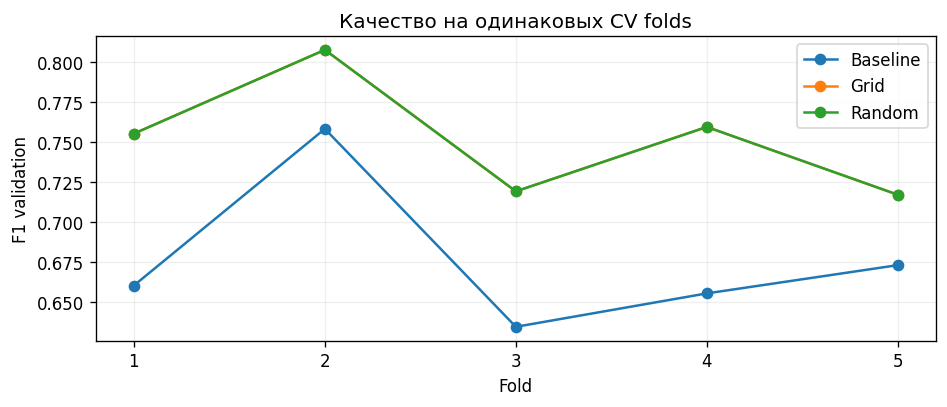

In [6]:
fold_scores = {'Baseline': base_cv['test_score']}
params = {'Baseline': {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__ccp_alpha': 0.0}}
for name, search in searches.items():
    fold_scores[name] = np.array([search.cv_results_[f'split{k}_test_score'][search.best_index_] for k in range(5)])
    params[name] = search.best_params_
means = {name: float(scores.mean()) for name, scores in fold_scores.items()}
selected = max(means, key=means.get)
selection = {'selected': selected, 'params': params[selected], 'criterion': 'max mean CV F1; tie: Baseline, Grid, Random', 'cv_means': means}
(OUT / 'selection_before_test.json').write_text(json.dumps(selection, indent=2), encoding='utf-8')
fold_table = pd.DataFrame(fold_scores, index=[f'Fold {i}' for i in range(1, 6)])
fold_table.to_csv(OUT / 'fold_scores.csv')
print(fold_table.round(4).to_string())
print('Победитель по CV:', selected, params[selected])
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, scores in fold_scores.items(): ax.plot(range(1, 6), scores, 'o-', label=name)
ax.set(xlabel='Fold', ylabel='F1 validation', xticks=range(1, 6), title='Качество на одинаковых CV folds')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); fig.savefig(OUT / 'folds.png'); plt.show()

**Вывод:** Grid и Random совпали по всем пяти CV-оценкам. Их разброс меньше, чем у baseline: стандартное отклонение **0.0369 против 0.0478**. На этих folds результат стал ровнее. По правилу разрешения ничьей выбираем **Grid**.

## 6. Как настройки влияют на качество

По очереди меняем один гиперпараметр, остальные оставляем как у выбранной модели. Строим графики F1 на обучающих и проверочных частях folds. Затенённая область — разброс CV-оценок (± одно стандартное отклонение).

**Как читаем графики:** низкое качество и на train, и на CV — признак недообучения. Рост train без улучшения CV — признак переобучения. Ищем область высокого CV при умеренной сложности.

Графики нужны для объяснения поведения дерева; выбранную модель по ним не меняем.

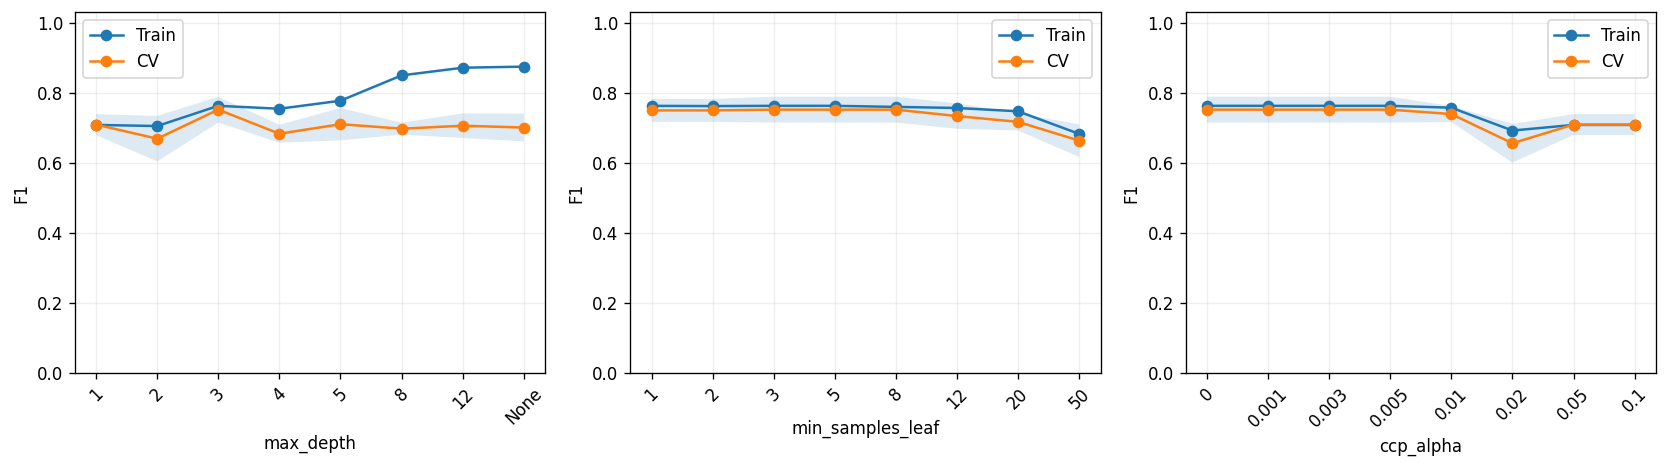

            parameter value  train_mean  cv_mean  cv_std
       clf__max_depth     1      0.7080   0.7090  0.0299
       clf__max_depth     2      0.7048   0.6687  0.0648
       clf__max_depth     3      0.7624   0.7516  0.0369
       clf__max_depth     4      0.7541   0.6828  0.0256
       clf__max_depth     5      0.7769   0.7100  0.0463
       clf__max_depth     8      0.8492   0.6972  0.0170
       clf__max_depth    12      0.8711   0.7057  0.0351
       clf__max_depth  None      0.8742   0.7005  0.0396
clf__min_samples_leaf     1      0.7623   0.7493  0.0328
clf__min_samples_leaf     2      0.7617   0.7493  0.0328
clf__min_samples_leaf     3      0.7624   0.7516  0.0369
clf__min_samples_leaf     5      0.7624   0.7516  0.0369
clf__min_samples_leaf     8      0.7594   0.7516  0.0369
clf__min_samples_leaf    12      0.7563   0.7332  0.0363
clf__min_samples_leaf    20      0.7468   0.7167  0.0247
clf__min_samples_leaf    50      0.6824   0.6632  0.0465
       clf__ccp_alpha     0    

In [7]:
curve_values = {'clf__max_depth': [1, 2, 3, 4, 5, 8, 12, None],
                'clf__min_samples_leaf': [1, 2, 3, 5, 8, 12, 20, 50],
                'clf__ccp_alpha': [0, .001, .003, .005, .01, .02, .05, .1]}
curve_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (param, values) in zip(axes, curve_values.items()):
    train_means, val_means, val_std = [], [], []
    for value in values:
        config = {**params[selected], param: value}
        result = cross_validate(clone(baseline).set_params(**config), X_train, y_train, cv=cv, scoring='f1', return_train_score=True, n_jobs=1)
        tm, vm, vs = result['train_score'].mean(), result['test_score'].mean(), result['test_score'].std(ddof=1)
        train_means.append(tm); val_means.append(vm); val_std.append(vs)
        curve_rows.append({'parameter': param, 'value': str(value), 'train_mean': tm, 'cv_mean': vm, 'cv_std': vs})
    xx = np.arange(len(values))
    ax.plot(xx, train_means, 'o-', label='Train')
    ax.plot(xx, val_means, 'o-', label='CV')
    ax.fill_between(xx, np.array(val_means)-val_std, np.array(val_means)+val_std, alpha=.15)
    ax.set(xticks=xx, xticklabels=[str(v) for v in values], xlabel=param.replace('clf__', ''), ylabel='F1', ylim=(0, 1.03))
    ax.tick_params(axis='x', rotation=45); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT / 'validation_curves.png')
fig.canvas.draw()
for ax, param in zip(axes, curve_values):
    bbox = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted()).expanded(1.04, 1.04)
    fig.savefig(OUT / (param.replace('clf__', '') + '.png'), bbox_inches=bbox)
plt.show()
curves = pd.DataFrame(curve_rows)
curves.to_csv(OUT / 'validation_curves.csv', index=False)
print(curves.round(4).to_string(index=False))

**Выводы по графикам**
- **Недообучение:** глубина 1–2, листья по 50 объектов или сильная обрезка дают слишком простые правила и низкое качество.
- **Разумная сложность:** глубина **3**; при ней листья **3–8** и `ccp_alpha` от **0 до 0.005** дают одинаковый высокий CV F1.
- **Переобучение:** при глубине **8 и выше** train F1 растёт до 0.85–0.87, а CV остаётся около 0.70 — хуже, чем у глубины 3.
- Кривые не обязаны быть плавными: дерево строит разбиения по Gini, а оцениваем мы F1. Влияние каждого параметра зависит от остальных настроек.

## 7. Финальная проверка на test

Обучаем baseline и победителей поисков на всём train. Теперь получаем предсказания на отложенных 180 пассажирах и считаем метрики.

Сравниваем **CV F1 и Test F1** трёх моделей. Финальную модель уже выбрали по CV: результат test не меняет этот выбор.

In [8]:
rows, predictions = [], pd.DataFrame({'Id': full.iloc[test_idx].Id.to_numpy(), 'y_true': y_test.to_numpy()})
fitted = {}
for name in ['Baseline', 'Grid', 'Random']:
    model = clone(baseline).set_params(**params[name]).fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    predictions[name] = pred
    scores = fold_scores[name]
    rows.append({'model': name, 'CV_F1': scores.mean(), 'CV_std': scores.std(ddof=1),
                 'CV_min': scores.min(), 'CV_max': scores.max(), 'Test_F1': f1_score(y_test, pred),
                 'Test_accuracy': accuracy_score(y_test, pred), 'Test_precision': precision_score(y_test, pred, zero_division=0),
                 'Test_recall': recall_score(y_test, pred, zero_division=0),
                 'Train_F1': f1_score(y_train, model.predict(X_train)),
                 'search_seconds': timings.get(name, 0), 'candidates': 1 if name=='Baseline' else 48})
summary = pd.DataFrame(rows).set_index('model')
summary.to_csv(OUT / 'summary.csv')
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
print(summary.round(4).to_string())
print('Финальная модель по CV:', selected)
print('Confusion matrix (строки — истинный класс):\n', confusion_matrix(y_test, predictions[selected]))
assert json.loads((OUT / 'selection_before_test.json').read_text())['selected'] == selected
assert np.isfinite(summary.select_dtypes('number').to_numpy()).all()
assert not {'Id', 'Survived'} & set(NUM + CAT)
metadata = {'source_commit': '6f7704934e19192d2e79281fdfd54961a0b16c29', 'data_sha256': hashlib.sha256((ROOT/'data/train.csv').read_bytes()).hexdigest(),
            'python': platform.python_version(), 'sklearn': sklearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
            'train_size': len(train_idx), 'test_size': len(test_idx), 'test_positives': int(y_test.sum()), 'selected': selected,
            'params': params, 'grid_space': grid_space, 'random_space': random_space,
            'baseline_full_parameters': baseline.named_steps['clf'].get_params(), 'checks': 'PASS'}
(OUT/'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

           CV_F1  CV_std  CV_min  CV_max  Test_F1  Test_accuracy  Test_precision  Test_recall  Train_F1  search_seconds  candidates
model                                                                                                                              
Baseline  0.6763  0.0478  0.6346  0.7581   0.7353         0.8000          0.7937       0.6849    0.9811          0.0000           1
Grid      0.7516  0.0369  0.7170  0.8073   0.7407         0.8056          0.8065       0.6849    0.7589          1.7922          48
Random    0.7516  0.0369  0.7170  0.8073   0.7313         0.8000          0.8033       0.6712    0.7540          1.7694          48
Финальная модель по CV: Grid
Confusion matrix (строки — истинный класс):
 [[95 12]
 [23 50]]


1692

**Вывод:** у Grid test F1 — **0.7407**, у Random — **0.7313**, у baseline — **0.7353**. Одинаковые CV-оценки не гарантируют одинакового test: параметры разные, и после обучения на всём train получаются разные деревья.

## 8. Насколько помогла оптимизация

Считаем изменение качества относительно baseline и проверяем, совпало ли улучшение на CV с результатом на test. Ниже — численные итоги, затем основные выводы.

In [9]:
for name in ['Grid', 'Random']:
    dc = summary.loc[name, 'CV_F1'] - summary.loc['Baseline', 'CV_F1']
    dt = summary.loc[name, 'Test_F1'] - summary.loc['Baseline', 'Test_F1']
    print(f'{name}: изменение CV F1 {dc:+.4f} ({100*dc:+.2f} п.п.); test F1 {dt:+.4f} ({100*dt:+.2f} п.п.).')
print('Наиболее низкий разброс folds:', summary.CV_std.idxmin())
for param in curve_values:
    part = curves[curves.parameter == param]
    low = part.loc[part.cv_mean.idxmin()]
    high = part.loc[part.cv_mean.idxmax()]
    gap = (part.train_mean - part.cv_mean)
    over = part.loc[gap.idxmax()]
    print(f'{param}: лучший на срезе {high.value}, CV={high.cv_mean:.4f}; худший {low.value}, CV={low.cv_mean:.4f}; максимальный train-CV gap={gap.max():.4f} при {over.value}.')
print('Все программные проверки пройдены. Test не участвовал в выборе параметров в этом запуске.')

Grid: изменение CV F1 +0.0752 (+7.52 п.п.); test F1 +0.0054 (+0.54 п.п.).
Random: изменение CV F1 +0.0752 (+7.52 п.п.); test F1 -0.0040 (-0.40 п.п.).
Наиболее низкий разброс folds: Grid
clf__max_depth: лучший на срезе 3, CV=0.7516; худший 2, CV=0.6687; максимальный train-CV gap=0.1737 при None.
clf__min_samples_leaf: лучший на срезе 3, CV=0.7516; худший 50, CV=0.6632; максимальный train-CV gap=0.0301 при 20.
clf__ccp_alpha: лучший на срезе 0, CV=0.7516; худший 0.02, CV=0.6556; максимальный train-CV gap=0.0363 при 0.02.
Все программные проверки пройдены. Test не участвовал в выборе параметров в этом запуске.


## 9. Итоги

- **Grid:** CV F1 вырос с 0.6763 до **0.7516**, test — с 0.7353 до **0.7407**. Улучшение на test небольшое: **0.54 процентного пункта**.
- **Random:** CV такой же — **0.7516**, но test F1 снизился до **0.7313**. Рост CV не гарантирует роста test: состав данных различается, а выбор лучшего CV среди многих попыток немного завышает ожидания.
- **Финальная модель — Grid:** глубина 3, минимум 3 объекта в листе, без обрезки. Она выбрана по заранее заданному правилу при равенстве CV.
- **Главный результат:** ограничение сложности уменьшило переобучение дерева. Большого улучшения на test мы не получили и значимое превосходство не доказали.

**Когда полезен Random Search:** при большом пространстве настроек и ограниченном времени. Он позволяет попробовать больше разных значений важных параметров. Для небольшой понятной сетки удобен Grid. Один запуск не доказывает, что один метод всегда лучше другого.

**Почему не подбираем по test:** многократный выбор по его результатам подстраивает модель под этот набор, и оценка перестаёт быть независимой.

**Ограничение нашей работы:** этот test уже использовался во второй лабораторной. Здесь по нему параметры не выбирались, но для полностью независимой проверки нужны новые размеченные данные.

**Источник:** [репозиторий лабораторных](https://github.com/batsuperflash/ml_course_mai/tree/6f7704934e19192d2e79281fdfd54961a0b16c29), `classification/lab02_titanic.ipynb` и `classification/data/train.csv`.